# 03 - Weekly baseline (no tenure shortcut)

In notebook 02 a user-level model scored PR-AUC 0.98, but mostly because insiders have fewer active days than everyone else. Here the unit is one **user-week**: a row exists when the user has at least one logon that week, features are the five counts computed **within that week only**, and the label is 1 if the week overlaps the user's attack window. The feature matrix has no tenure or calendar column.

Folds come from `make_folds` on users (same 5x5 settings as before) and every user's weeks go to the same side, so no user is in both train and test. Three **diagnostic controls** look for new shortcuts: calendar week only, weeks since the user first appeared, and weeks until the user's last appearance (that last one uses future information on purpose, as a leakage measurement only).

In [1]:
%load_ext autoreload
%autoreload 2

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier

from itgnn.data import load_config, prepare
from itgnn.evaluation import make_folds, evaluate_scores
from itgnn.windows import (WEEK_FEATURE_COLS, load_attack_windows, make_weekly_features,
                           label_weeks, week_masks)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
cfg = load_config("configs/config.yaml")
SEED, QS = cfg["seed"], [0.25, 0.5, 1, 2]
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format

d = prepare(cfg)
users, labels = d["users"], d["labels"]
folds = make_folds(users, labels, cfg["cv"]["n_splits"], cfg["cv"]["n_repeats"], SEED)
windows = load_attack_windows(cfg["raw_dir"])
weekly = make_weekly_features(d["logon"], d["device"], d["file"], users)
weekly["label"] = label_weeks(weekly, windows)

## 1. The weekly dataset

How many user-weeks there are, how many are malicious, and which scenarios they come from. The "no Logon that week, no row" rule discards device and file events in weeks without a logon; we count how many.

In [2]:
ins = pd.read_csv(Path(cfg["raw_dir"]) / "answers" / "insiders.csv")
scen = ins[ins["dataset"].astype(str) == "4.2"].set_index("user")["scenario"]
n_mal = int(weekly["label"].sum())
print(f"rows (user-weeks): {len(weekly):,} | users: {weekly['user'].nunique()} | weeks span {weekly['week_start'].min().date()} to {weekly['week_start'].max().date()}")
print(f"malicious weeks: {n_mal:,} ({n_mal / len(weekly):.2%}) | insiders with >=1 attack week: {weekly.loc[weekly['label']==1, 'user'].nunique()} of {len(windows)}")
print("weeks per user:", weekly.groupby("user").size().describe().round(1).to_dict())
mw = weekly[weekly["label"] == 1].assign(scenario=lambda x: x["user"].map(scen))
display(mw.groupby("scenario").agg(malicious_weeks=("label", "size"), insiders=("user", "nunique")))
dropped = {}
for n in ["device", "file"]:
    ev = d[n][d[n]["user"].isin(users)]
    dropped[n] = {"events (selected users)": len(ev), "kept in weekly rows": int(weekly[f"n_{n}"].sum())}
    dropped[n]["dropped (no logon that week)"] = dropped[n]["events (selected users)"] - dropped[n]["kept in weekly rows"]
    dropped[n]["dropped %"] = dropped[n]["dropped (no logon that week)"] / dropped[n]["events (selected users)"] * 100
display(pd.DataFrame(dropped).T)
display(weekly[WEEK_FEATURE_COLS].describe().T)

rows (user-weeks): 67,238 | users: 1000 | weeks span 2009-12-28 to 2011-05-16
malicious weeks: 322 (0.48%) | insiders with >=1 attack week: 70 of 70
weeks per user: {'count': 1000.0, 'mean': 67.2, 'std': 13.2, 'min': 5.0, '25%': 72.0, '50%': 72.0, '75%': 72.0, 'max': 73.0}


,malicious_weeks,insiders
scenario,,
1,52,30
2,260,30
3,10,10


,events (selected users),kept in weekly rows,dropped (no logon that week),dropped %
device,"405,380.000","405,380.000",0.000,0.000
file,"445,581.000","445,581.000",0.000,0.000


,count,mean,std,min,25%,50%,75%,max
n_logon,"67,238.000",6.999,3.789,1.000,5.000,5.000,9.000,35.000
n_after_hours,"67,238.000",0.472,2.155,0.000,0.000,0.000,0.000,23.000
n_pcs,"67,238.000",1.672,2.774,1.000,1.000,1.000,1.000,29.000
n_device,"67,238.000",6.029,18.346,0.000,0.000,0.000,0.000,170.000
n_file,"67,238.000",6.627,21.985,0.000,0.000,0.000,0.000,208.000


## 2. Where attack weeks fall in time

Calendar clustering would let a model learn "summer 2010 is risky" instead of behaviour. The second plot shows attack weeks relative to each user's **last** week in the data: insiders leave shortly after attacking, so attack weeks near the end would let a model learn disappearance. Both are tested explicitly by the controls below.

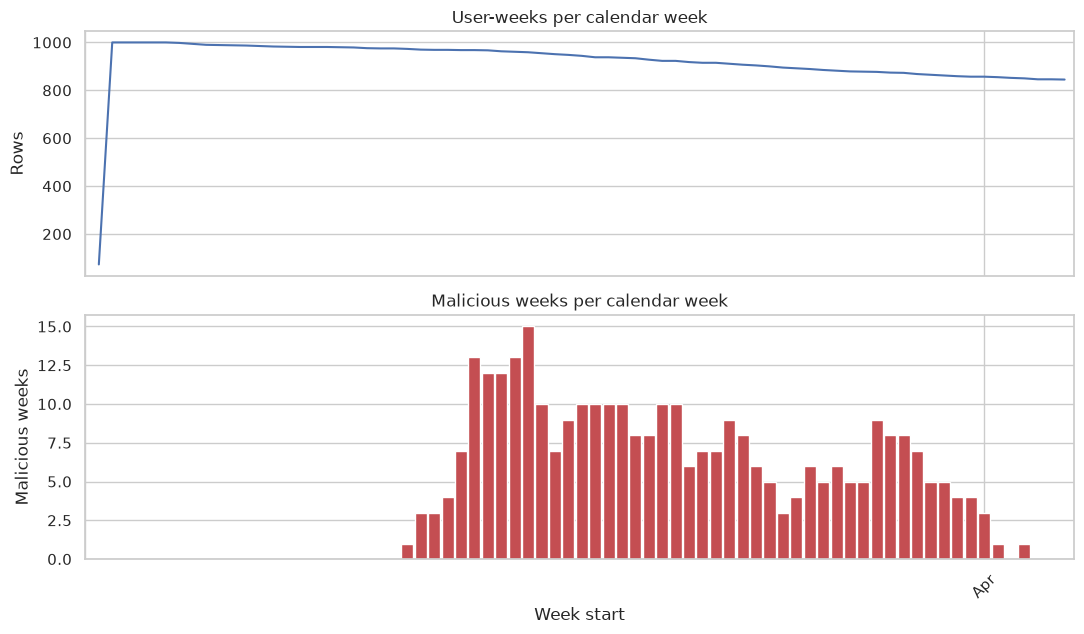

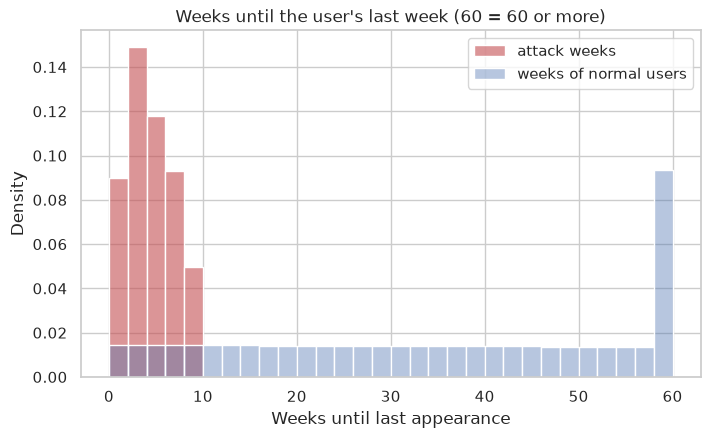

attack weeks: median weeks until user's last week = 4.0
share of insiders whose last week is within 4 weeks of their last attack week: 1.0
normal users' weeks until last: median 35.0


In [3]:
g = weekly.groupby("week_start")
origin, ends = weekly["week_start"].min(), weekly.groupby("user")["week_start"].transform("max")
first = weekly.groupby("user")["week_start"].transform("min")
ctrl = pd.DataFrame({  # diagnostic-only columns; never part of the real feature matrix
    "cal_week": (weekly["week_start"] - origin).dt.days // 7,
    "weeks_since_first": (weekly["week_start"] - first).dt.days // 7,
    "weeks_until_last": (ends - weekly["week_start"]).dt.days // 7,
})
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
g.size().plot(ax=axes[0]); axes[0].set(title="User-weeks per calendar week", ylabel="Rows")
g["label"].sum().plot(kind="bar", ax=axes[1], width=0.9, color="#c44e52")
axes[1].set(title="Malicious weeks per calendar week", xlabel="Week start", ylabel="Malicious weeks")
axes[1].set_xticks(axes[1].get_xticks()[::6]); axes[1].set_xticklabels([x.get_text()[:10] for x in axes[1].get_xticklabels()], rotation=45)
plt.tight_layout(); plt.show()

ins_users = set(labels)
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(0, 62, 2)
sns.histplot(ctrl.loc[weekly["label"] == 1, "weeks_until_last"].clip(upper=60), bins=bins, stat="density", color="#c44e52", alpha=0.6, label="attack weeks", ax=ax)
sns.histplot(ctrl.loc[~weekly["user"].isin(ins_users), "weeks_until_last"].clip(upper=60), bins=bins, stat="density", color="#4c72b0", alpha=0.4, label="weeks of normal users", ax=ax)
ax.set(title="Weeks until the user's last week (60 = 60 or more)", xlabel="Weeks until last appearance", ylabel="Density"); ax.legend()
plt.show()
mal_u = weekly.loc[weekly["label"] == 1, "user"]
print("attack weeks: median weeks until user's last week =", ctrl.loc[weekly["label"] == 1, "weeks_until_last"].median())
print("share of insiders whose last week is within 4 weeks of their last attack week:",
      round((weekly[weekly["label"] == 1].assign(u=ctrl["weeks_until_last"]).groupby("user")["u"].min() <= 4).mean(), 3))
print("normal users' weeks until last: median", ctrl.loc[~weekly["user"].isin(ins_users), "weeks_until_last"].median())

## 3. Models and cross-validation

Fixed hyperparameters (the same as notebook 02), class weights recomputed from every training fold, the same 25 folds for every model. Real models see only the five weekly counts. Controls are small random forests on a single column: `cal_week`, `weeks_since_first`, `weeks_until_last`. If a control scores far above the prevalence, that column is a shortcut and the dataset still leaks it.

In [4]:
def lr():
    return make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                         LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))
def rf():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=SEED)
def small_rf():
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=SEED)
def xgb(ytr):
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                         scale_pos_weight=(ytr == 0).sum() / (ytr == 1).sum(), n_jobs=4, random_state=SEED, verbosity=0)
fit_score = lambda m, Xtr, ytr, Xte: m.fit(Xtr, ytr).predict_proba(Xte)[:, 1]

X, y = weekly[WEEK_FEATURE_COLS], weekly["label"]
MODELS = {  # name -> (feature frame, scorer)
    "constant prior": (X, lambda Xtr, ytr, Xte: np.full(len(Xte), ytr.mean())),
    "n_device > 0": (X, lambda Xtr, ytr, Xte: (Xte["n_device"] > 0).to_numpy(float)),
    "logistic regression": (X, lambda Xtr, ytr, Xte: fit_score(lr(), Xtr, ytr, Xte)),
    "random forest": (X, lambda Xtr, ytr, Xte: fit_score(rf(), Xtr, ytr, Xte)),
    "xgboost": (X, lambda Xtr, ytr, Xte: fit_score(xgb(ytr), Xtr, ytr, Xte)),
    "control: calendar week": (ctrl[["cal_week"]], lambda Xtr, ytr, Xte: fit_score(small_rf(), Xtr, ytr, Xte)),
    "control: weeks since first": (ctrl[["weeks_since_first"]], lambda Xtr, ytr, Xte: fit_score(small_rf(), Xtr, ytr, Xte)),
    "control: weeks until last (future)": (ctrl[["weeks_until_last"]], lambda Xtr, ytr, Xte: fit_score(small_rf(), Xtr, ytr, Xte)),
}
ORDER = list(MODELS)
metric_rows, oof_parts = [], []
for f in folds:
    tr, te = week_masks(weekly, f)
    for name, (Xm, fn) in MODELS.items():
        s = fn(Xm[tr], y[tr], Xm[te])
        ev = evaluate_scores(y[te].to_numpy(), s, k=100)
        metric_rows.append({"model": name, "repeat": f["repeat"], "fold": f["fold"], "pr_auc": ev["pr_auc"], "roc_auc": ev["roc_auc"]})
        oof_parts.append(pd.DataFrame({"user": weekly.loc[te, "user"].to_numpy(), "week_start": weekly.loc[te, "week_start"].to_numpy(),
                                       "repeat": f["repeat"], "fold": f["fold"], "model": name, "score": s, "label": y[te].to_numpy()}))
results = pd.DataFrame(metric_rows)
oof = pd.concat(oof_parts, ignore_index=True)
oof.drop(columns="fold").to_parquet("results/weekly_baseline_oof_scores.parquet", index=False)
print("saved results/weekly_baseline_oof_scores.parquet:", oof.shape)
prev = y.mean()

saved results/weekly_baseline_oof_scores.parquet: (2689520, 7)


## 4. Results: week-level PR-AUC and ROC-AUC

Mean ± std over the 25 folds. PR-AUC of the constant prior equals the prevalence. The controls are listed next to the real models.

In [5]:
S = results.groupby("model")[["pr_auc", "roc_auc"]].agg(["mean", "std"]).loc[ORDER]
tbl = pd.DataFrame({m.replace("_", "-").upper(): S[m].apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1) for m in ["pr_auc", "roc_auc"]})
display(tbl)
print(f"prevalence (PR-AUC floor): {prev:.4f}")

,PR-AUC,ROC-AUC
model,,
constant prior,0.005 ± 0.001,0.500 ± 0.000
n_device > 0,0.023 ± 0.004,0.896 ± 0.013
logistic regression,0.054 ± 0.024,0.952 ± 0.012
random forest,0.283 ± 0.071,0.969 ± 0.023
xgboost,0.343 ± 0.087,0.981 ± 0.008
control: calendar week,0.009 ± 0.002,0.719 ± 0.036
control: weeks since first,0.009 ± 0.002,0.717 ± 0.036
control: weeks until last (future),0.044 ± 0.005,0.941 ± 0.006


prevalence (PR-AUC floor): 0.0048


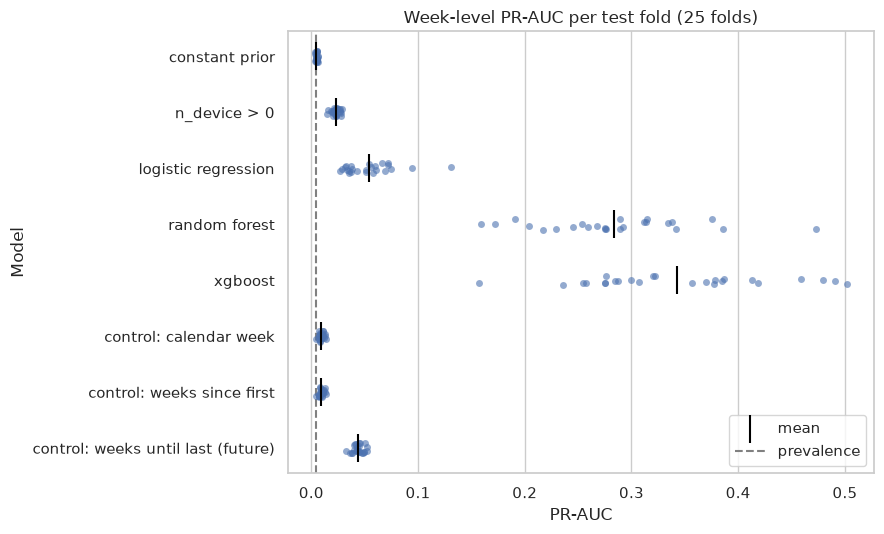

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.stripplot(data=results, y="model", x="pr_auc", order=ORDER, orient="h", alpha=0.6, size=5, ax=ax)
ax.scatter(results.groupby("model")["pr_auc"].mean().loc[ORDER].values, range(len(ORDER)), marker="|", s=400, color="black", zorder=3, label="mean")
ax.axvline(prev, color="gray", ls="--", label="prevalence")
ax.set(title="Week-level PR-AUC per test fold (25 folds)", xlabel="PR-AUC", ylabel="Model"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 5. Pooled out-of-fold PR curves

Within one repeat every user-week is scored once by a model that never saw that user, so the five folds pool into one curve. Thick line = repeat 0, thin = the other repeats. Controls are dashed; the grey dashed line is the prevalence.

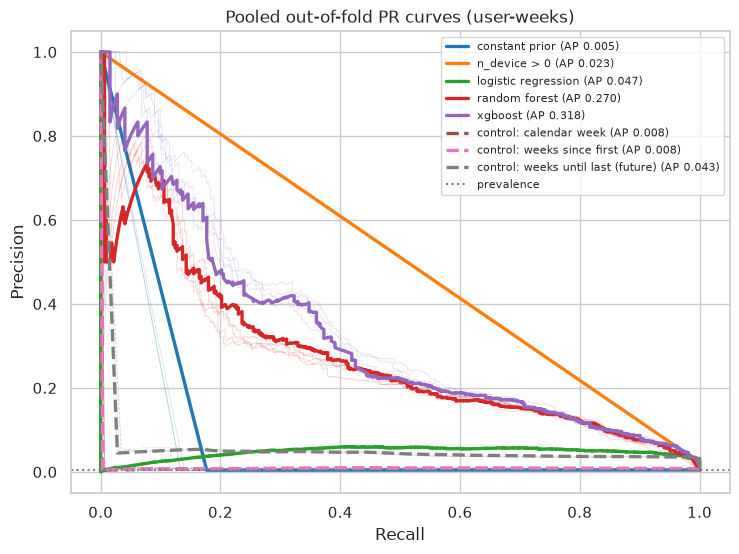

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 6))
pal = dict(zip(ORDER, sns.color_palette("tab10", len(ORDER))))
for name in ORDER:
    for r in sorted(oof["repeat"].unique()):
        sub = oof[(oof["model"] == name) & (oof["repeat"] == r)]
        p, rc, _ = precision_recall_curve(sub["label"], sub["score"])
        ax.plot(rc, p, color=pal[name], ls="--" if name.startswith("control") else "-", lw=2.4 if r == 0 else 0.6, alpha=1 if r == 0 else 0.2,
                label=f"{name} (AP {average_precision_score(sub['label'], sub['score']):.3f})" if r == 0 else None)
ax.axhline(prev, color="gray", ls=":", label="prevalence")
ax.set(title="Pooled out-of-fold PR curves (user-weeks)", xlabel="Recall", ylabel="Precision"); ax.legend(fontsize=8)
plt.show()

## 6. Paired differences (PR-AUC)

Same folds for every model, so we can subtract fold by fold. Repeated-CV folds are correlated (they share users and training data), so the std understates the true uncertainty: descriptive only, not a significance test.

In [8]:
pv = results.pivot_table(index=["repeat", "fold"], columns="model", values="pr_auc")
rows = {}
for b in ["n_device > 0", "control: calendar week", "control: weeks since first", "control: weeks until last (future)"]:
    dl = pv["random forest"] - pv[b]
    rows[f"random forest - {b}"] = {"mean diff": dl.mean(), "std": dl.std(), "folds where RF wins": f"{(dl > 0).mean():.0%}"}
display(pd.DataFrame(rows).T)

,mean diff,std,folds where RF wins
random forest - n_device > 0,0.261,0.069,100%
random forest - control: calendar week,0.274,0.069,100%
random forest - control: weeks since first,0.274,0.069,100%
random forest - control: weeks until last (future),0.240,0.069,100%


## 7. Alert budget

An analyst can only look at so many weeks. In each test fold we flag the top q% of user-weeks by score (ties broken at random with a fixed seed). For each repeat we pool the 5 test folds so every user appears once, then count (a) how many of the 70 insiders have **at least one attack week flagged**, and (b) how many distinct **normal** users (not in the answer key) have any week flagged. Mean ± std over the 5 repeats. Note that flagging the top q% across the whole period is easier than a real weekly workflow, where each week would need its own fixed budget.

In [9]:
rng = np.random.default_rng(SEED)
rows = []
for (name, r), g in oof.groupby(["model", "repeat"]):
    flagged = {q: [] for q in QS}
    for _, gf in g.groupby("fold"):
        order = np.lexsort((rng.random(len(gf)), -gf["score"].to_numpy()))
        for q in QS:
            flagged[q].append(gf.iloc[order[: int(np.ceil(q / 100 * len(gf)))]])
    for q in QS:
        fl = pd.concat(flagged[q])
        caught = fl.loc[fl["label"] == 1, "user"].nunique()
        normal = fl.loc[~fl["user"].isin(labels), "user"].nunique()
        rows.append({"model": name, "q%": q, "repeat": r, "insiders caught": caught, "normal users flagged": normal, "weeks flagged": len(fl)})
bud = pd.DataFrame(rows)
agg = bud.groupby(["model", "q%"])[["insiders caught", "normal users flagged", "weeks flagged"]].agg(["mean", "std"])
out = pd.DataFrame({c: agg[c].apply(lambda r: f"{r['mean']:.1f} ± {r['std']:.1f}", axis=1) for c in ["insiders caught", "normal users flagged", "weeks flagged"]})
display(out.reindex(ORDER, level=0))
print(f"insiders in total: {len(windows)} | normal users in total: {len(users) - len(windows)}")

insiders caught normal users flagged  \
model                              q%                                           
constant prior                     0.250       0.6 ± 0.9          146.8 ± 6.4   
                                   0.500       2.0 ± 2.4          271.4 ± 9.2   
                                   1.000       4.0 ± 2.8         459.4 ± 12.6   
                                   2.000       7.6 ± 3.0         689.8 ± 10.0   
n_device > 0                       0.250       3.4 ± 2.3          100.8 ± 1.3   
                                   0.500       6.8 ± 3.6          147.4 ± 1.9   
                                   1.000      12.8 ± 3.8          179.8 ± 2.6   
                                   2.000      23.4 ± 3.4          190.8 ± 1.6   
logistic regression                0.250       2.6 ± 2.1           14.8 ± 2.4   
                                   0.500       5.2 ± 3.5           18.0 ± 1.2   
                                   1.000       9.4 ± 4.0           25.8 ± 1.6   
                                   2.000      27.0 ± 1.0           46.6 ± 5.1   
random forest                      0.250      34.4 ± 1.3           10.6 ± 1.1   
                                   0.500      39.8 ± 0.8           17.2 ± 4.5   
                                   1.000      45.8 ± 2.2           38.2 ± 4.8   
                                   2.000      56.2 ± 1.3           86.4 ± 2.3   
xgboost                            0.250      38.6 ± 2.2           15.6 ± 3.6   
                                   0.500      43.4 ± 2.4           20.8 ± 4.7   
                                   1.000      46.4 ± 1.7           27.2 ± 4.3   
                                   2.000      53.2 ± 1.8           58.4 ± 2.7   
control: calendar week             0.250       2.6 ± 2.2          161.8 ± 3.4   
                                   0.500       4.8 ± 1.6          316.0 ± 4.9   
                                   1.000       8.0 ± 0.7          633.0 ± 2.8   
                                   2.000      13.0 ± 2.5          896.4 ± 1.1   
control: weeks since first         0.250       1.8 ± 0.4          160.4 ± 1.8   
                                   0.500       4.2 ± 0.4          318.4 ± 3.4   
                                   1.000       8.0 ± 1.7          632.6 ± 5.6   
                                   2.000      13.6 ± 2.7          896.8 ± 1.6   
control: weeks until last (future) 0.250       9.2 ± 3.1          159.8 ± 3.7   
                                   0.500      17.6 ± 3.6          317.8 ± 4.1   
                                   1.000      34.8 ± 3.8          631.0 ± 6.1   
                                   2.000      54.0 ± 0.0          930.0 ± 0.0   

                                         weeks flagged  
model                              q%                   
constant prior                     0.250   170.4 ± 0.5  
                                   0.500   338.8 ± 0.4  
                                   1.000   674.6 ± 0.9  
                                   2.000  1347.2 ± 0.8  
n_device > 0                       0.250   170.4 ± 0.5  
                                   0.500   338.8 ± 0.4  
                                   1.000   674.6 ± 0.9  
                                   2.000  1347.2 ± 0.8  
logistic regression                0.250   170.4 ± 0.5  
                                   0.500   338.8 ± 0.4  
                                   1.000   674.6 ± 0.9  
                                   2.000  1347.2 ± 0.8  
random forest                      0.250   170.4 ± 0.5  
                                   0.500   338.8 ± 0.4  
                                   1.000   674.6 ± 0.9  
                                   2.000  1347.2 ± 0.8  
xgboost                            0.250   170.4 ± 0.5  
                                   0.500   338.8 ± 0.4  
                                   1.000   674.6 ± 0.9  
                                   2.000  1347.2 ± 0.8  
control: calendar week          

insiders in total: 70 | normal users in total: 930


## Key takeaways

- **Dataset.** 67,238 user-weeks (1,000 users, 2009-12-28 to 2011-05-16), of which 322 (0.48%) are attack weeks covering all 70 insiders. Scenario 2 supplies 260 of them (30 insiders), scenario 1 supplies 52 and scenario 3 supplies 10. Results are therefore dominated by scenario 2. The "no Logon that week, no row" rule dropped 0 device and 0 file events: every such event falls in a week with a logon.
- **Much harder than notebook 02, as expected.** With the tenure shortcut gone, the best week-level PR-AUC is 0.343 ± 0.087 for XGBoost and 0.283 ± 0.071 for the random forest, against a prevalence of 0.005 (constant prior 0.005). The 0.98 of notebook 02 was mostly tenure and is not comparable (different unit, different label). Logistic regression reaches only 0.054 PR-AUC (ROC-AUC 0.952) and the `n_device > 0` rule 0.023 (ROC-AUC 0.896). XGBoost vs random forest was not tested: the two spreads overlap, so I would not rank them.
- **Controls.** The calendar-week control scores PR-AUC 0.009 (ROC-AUC 0.719) and weeks-since-first 0.009 (0.717), about twice the prevalence but far below the real models (paired difference of 0.27 PR-AUC, RF winning in all 25 folds). The two are nearly identical because most users first appear in the first week. So calendar time is a weak shortcut, not the main driver. The future-looking control (weeks until the user's last appearance) scores PR-AUC 0.044 and ROC-AUC 0.941: that is a real leak in the data. Every insider's last attack week is within 4 weeks of their last week in the data (insiders vanish after attacking), while the median normal user's weeks are 35 weeks from their last. The real models cannot see this column, yet behaviour around an exit may still correlate with it, so some of the signal could be leaving-related. I cannot separate that here.
- **Alert budget (pooled over folds, mean ± std over 5 repeats; 70 insiders, 930 normal users).** Flagging the top 0.25% of weeks (about 170 weeks): random forest catches 34.4 ± 1.3 insiders and flags 10.6 ± 1.1 normal users; XGBoost 38.6 ± 2.2 and 15.6 ± 3.6. At 2% (about 1,347 weeks): random forest 56.2 ± 1.3 insiders and 86.4 ± 2.3 normal users; XGBoost 53.2 ± 1.8 and 58.4 ± 2.7. The `n_device > 0` rule catches 23.4 insiders but flags 190.8 normal users at 2%, and a random flag at 2% catches 7.6 and flags 689.8. The future-looking control at 2% catches 54 insiders but flags all 930 normal users, which shows why the normal-users-flagged column must be read next to the catch count.
- **Limitations.**
  - Flagging the top q% across the whole period is easier than a weekly analyst workflow, where each week would need its own fixed budget and the reviewer would not know which weeks are quiet in advance.
  - A week counts as malicious if it overlaps the attack window at all, even for a day, and the windows last up to 58 days, so many labelled weeks are only partly or weakly attack-related, which caps precision.
  - With about 14 insiders per test fold, fold-to-fold spread is large, and repeated-CV folds are correlated, so the stds understate uncertainty.
  - Hyperparameters are fixed, not tuned, and the first and last calendar weeks are partial.
  - There are no per-user history features (out of scope here), so a user who always uses removable drives looks the same as one who just started. Those features are the obvious next step.